In [52]:
import pandas as pd
import numpy as np

student_df = pd.read_csv('../data/raw/student_mental_health.csv')


In [74]:
print(student_df.head())
print('#'*100)
student_df.info()
print('#'*100)
print(f'shape: {student_df.shape}')
print('#'*100)
print(f'column types: {student_df.dtypes}')




  Student_ID  Age  Gender  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week  \
0    STU0001   22    Male              3          6.6                  17.6   
1    STU0002   21    Male              4          5.6                  22.4   
2    STU0003   22    Male              5          7.1                  28.1   
3    STU0004   24    Male              1          4.5                  14.8   
4    STU0005   20  Female              1          6.7                  17.2   

    GPA  Social_Media_Hours  Screen_Time_Hours Physical_Activity  \
0  2.91                 6.9                7.5          Moderate   
1  2.92                 7.6               11.5               Low   
2  2.68                 6.5                8.9               Low   
3  2.23                 5.5                7.6              High   
4  2.69                 4.3                7.0          Moderate   

   Financial_Stress  Family_Support  Attendance_Rate Part_Time_Job  \
0               8.5             4.0           

In [84]:
print("Missing values per column:")
print(student_df.isna().sum())

print("\nDuplicate rows:", student_df.duplicated().sum())
print("Duplicate Student_ID values:", student_df["Student_ID"].duplicated().sum())
print("Attendance_Rate values outside 0-100:", (student_df["Attendance_Rate"].notna() & ~student_df["Attendance_Rate"].between(0, 100)).sum())
print(student_df.describe(include="number"))

Missing values per column:
Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

Duplicate rows: 0
Duplicate Student_ID values: 0
Attendance_Rate values outside 0-100: 0
               Age  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week  \
count  2000.000000    2000.000000  1938.000000           2000.000000   
mean     21.131500       2.630000     6.758875             19.997900   
std       2.139275       

In [55]:
num_cols = student_df.select_dtypes(include="number").columns
num_cols

Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='str')

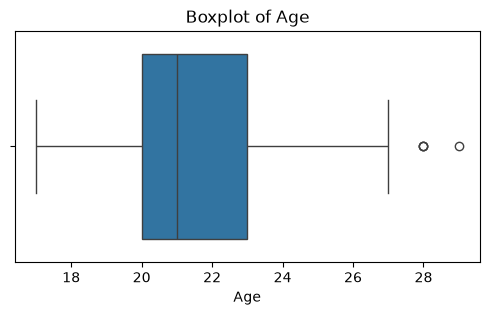

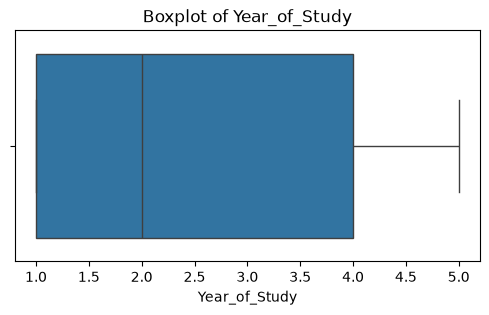

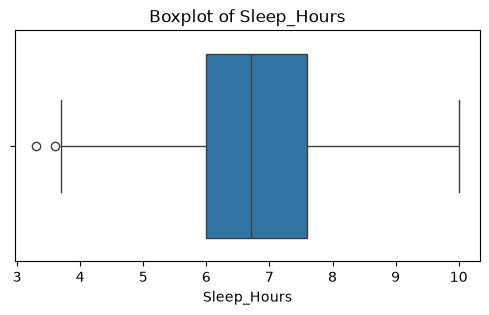

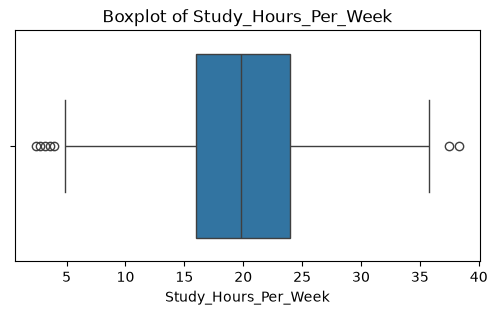

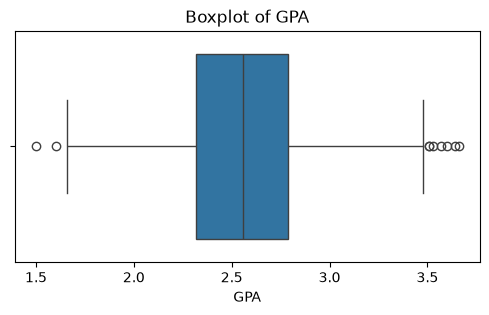

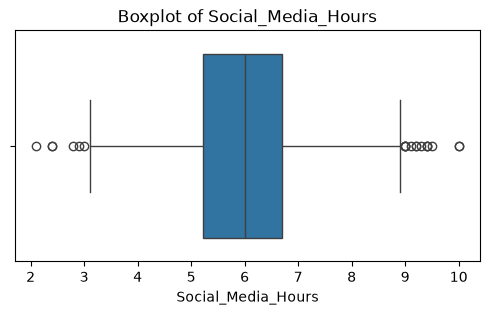

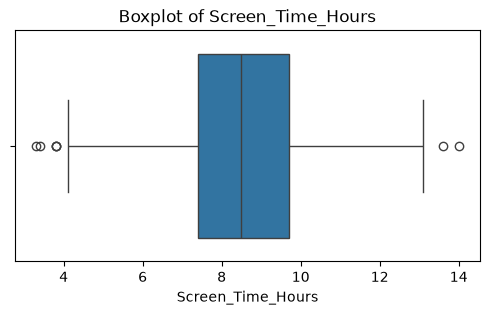

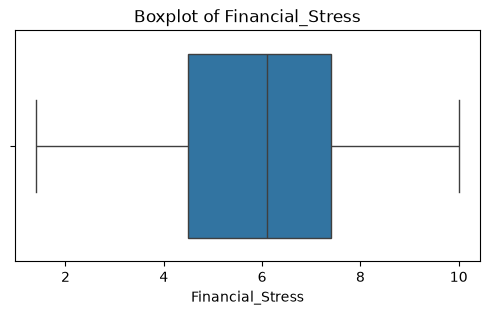

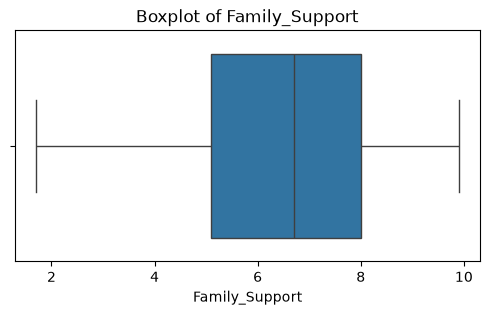

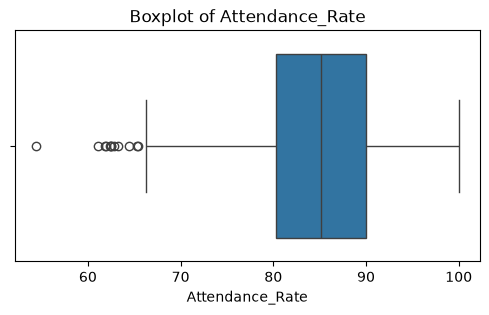

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in num_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=student_df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [ ]:
for col in num_cols:
    Q1 = student_df[col].quantile(0.25)
    Q3 = student_df[col].quantile(0.75)

    IQR = Q3-Q1

    lower_bound = Q1 - 1.5*IQR
    upper_bound = Q3 + 1.5*IQR


    outlier = student_df[(student_df[col]<lower_bound)|(student_df[col]>upper_bound)][col]
    print(f"col: {col}")
    print(f"lower_bound: {lower_bound}")
    print(f"upper_bound: {upper_bound}")
    print(f"number of outliers: {len(outlier)}")
    print("outlier values:")
    print(sorted(outlier.tolist()))


col: Age
lower_bound: 15.5
upper_bound: 27.5
number of outliers: 4
outlier values:
[28, 28, 28, 29]
col: Year_of_Study
lower_bound: -3.5
upper_bound: 8.5
number of outliers: 0
outlier values:
[]
col: Sleep_Hours
lower_bound: 3.6000000000000005
upper_bound: 10.0
number of outliers: 2
outlier values:
[3.3, 3.6]
col: Study_Hours_Per_Week
lower_bound: 4.0
upper_bound: 36.0
number of outliers: 7
outlier values:
[2.4, 2.7, 3.2, 3.6, 3.9, 37.5, 38.3]
col: GPA
lower_bound: 1.6149999999999995
upper_bound: 3.495
number of outliers: 9
outlier values:
[1.5, 1.6, 3.51, 3.51, 3.53, 3.57, 3.6, 3.64, 3.66]
col: Social_Media_Hours
lower_bound: 3.012499999999999
upper_bound: 8.912500000000001
number of outliers: 20
outlier values:
[2.1, 2.4, 2.4, 2.8, 2.9, 3.0, 9.0, 9.0, 9.0, 9.0, 9.1, 9.2, 9.2, 9.3, 9.4, 9.4, 9.4, 9.5, 10.0, 10.0]
col: Screen_Time_Hours
lower_bound: 3.950000000000002
upper_bound: 13.149999999999999
number of outliers: 7
outlier values:
[3.3, 3.4, 3.8, 3.8, 3.8, 13.6, 14.0]
col: Financi

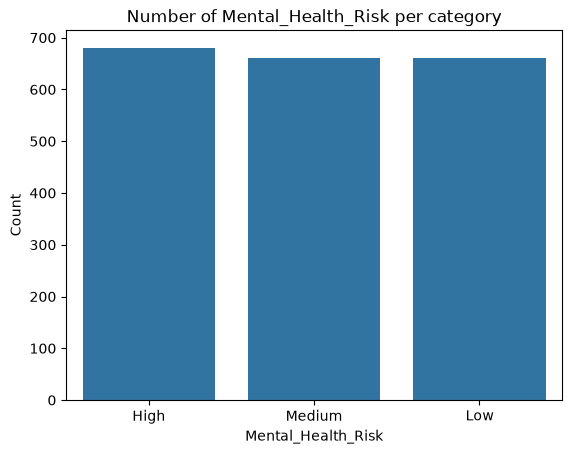

In [61]:
sns.countplot(data=student_df,x="Mental_Health_Risk")
plt.xlabel("Mental_Health_Risk")
plt.ylabel("Count")
plt.title("Number of Mental_Health_Risk per category")
plt.show()

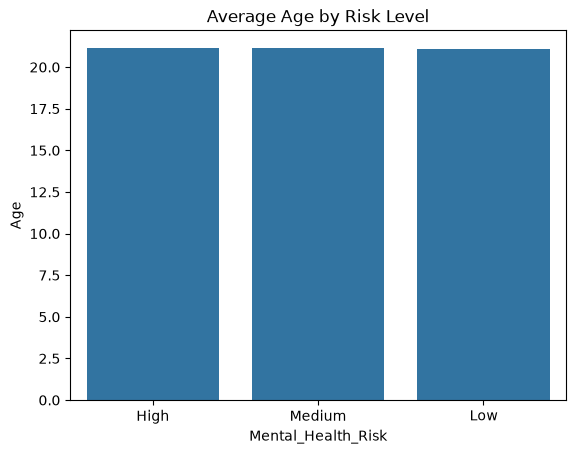

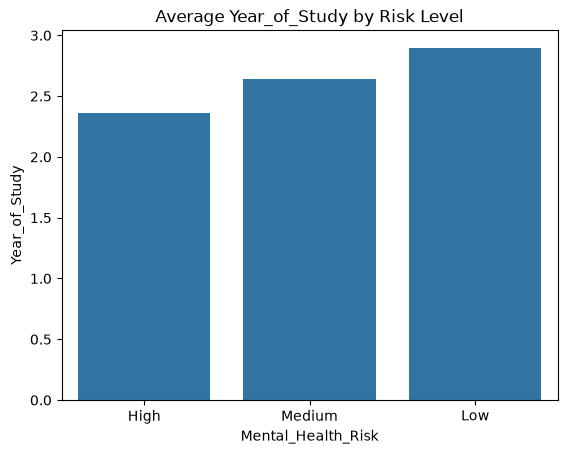

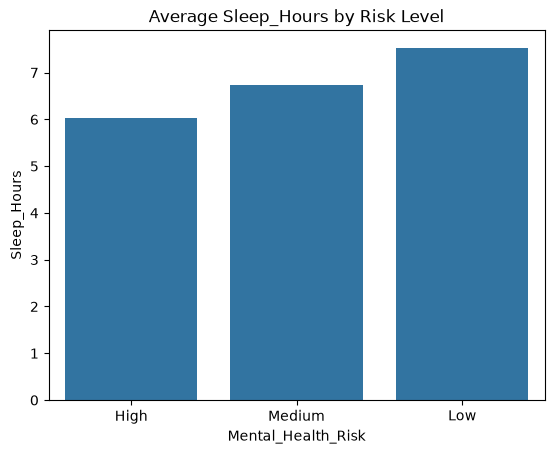

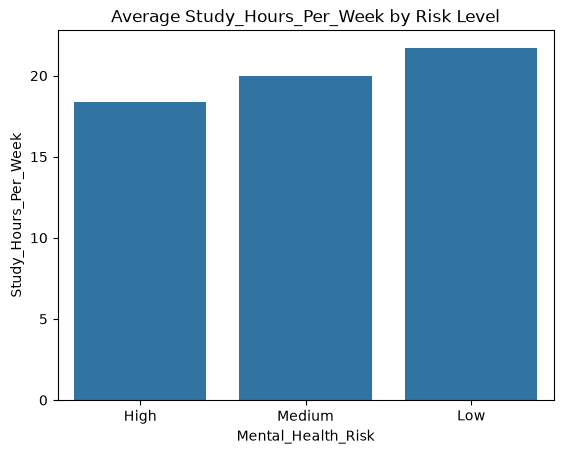

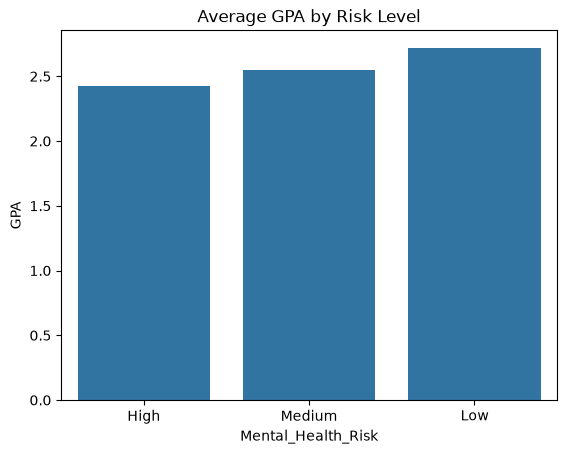

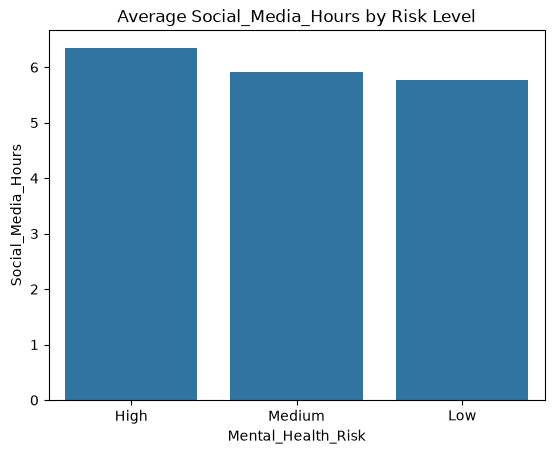

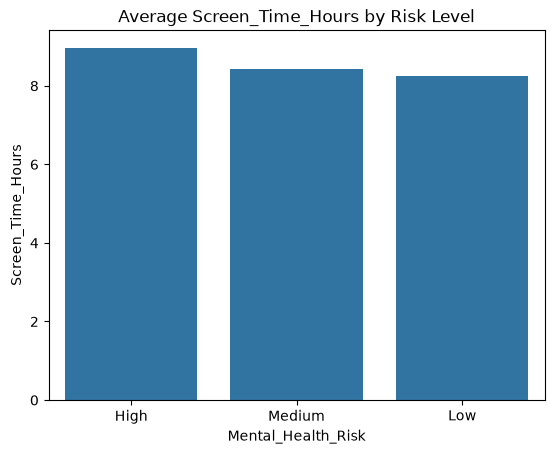

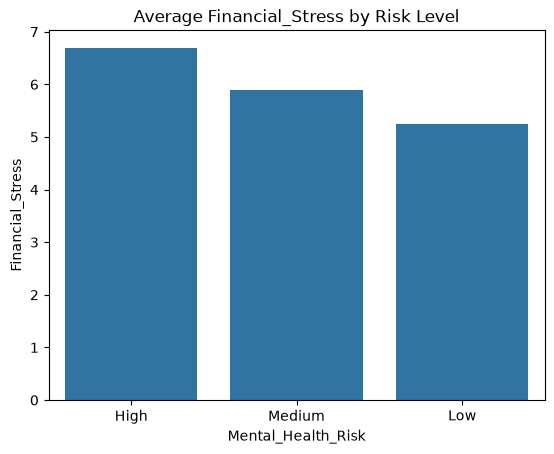

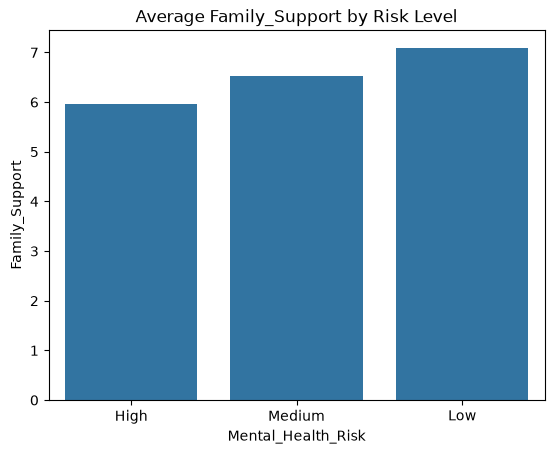

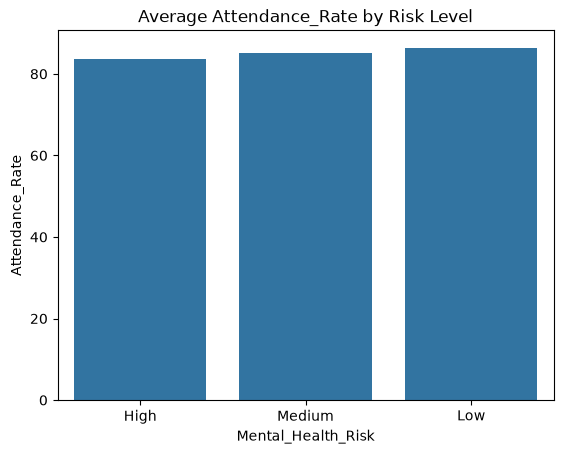

In [63]:
for col in num_cols:
    if col!='Mental_Health_Risk':
        sns.barplot(data=student_df,x=student_df['Mental_Health_Risk'],y=col,errorbar=None)
        plt.title(f"Average {col} by Risk Level")
        plt.show()

<Axes: >

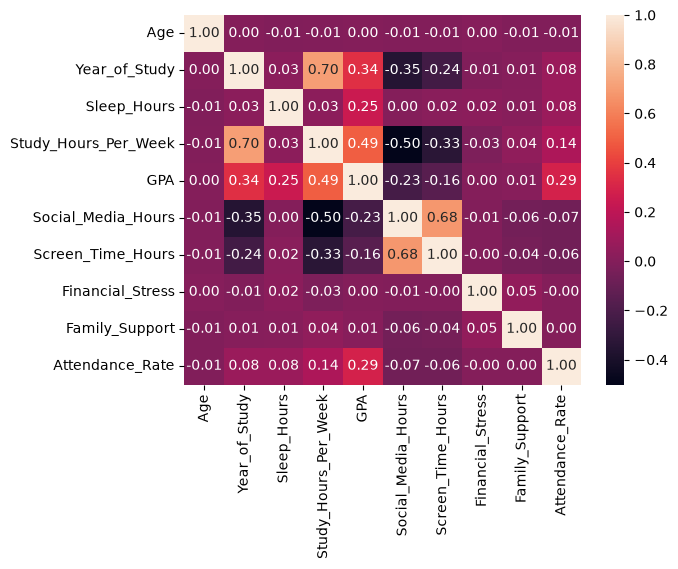

In [86]:
corr = student_df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

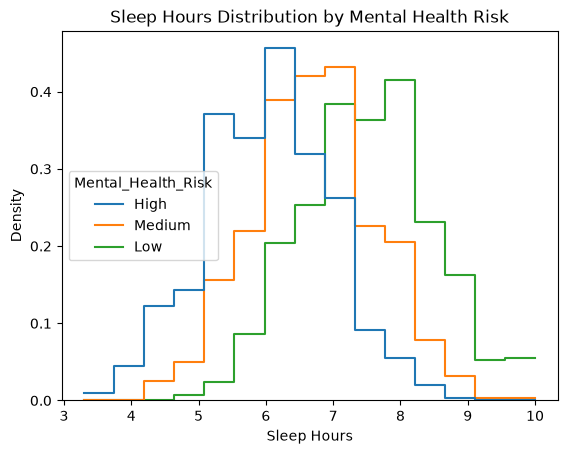

In [87]:
sns.histplot(
    data=student_df,
    x="Sleep_Hours",
    hue="Mental_Health_Risk",
    bins=15,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Sleep Hours Distribution by Mental Health Risk")
plt.xlabel("Sleep Hours")
plt.ylabel("Density")
plt.show()